<a href="https://colab.research.google.com/github/JuanCappelletti/12-RNN/blob/master/curva%20de%20bombas%20de%20rio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


BOMBA SNZ 600-510/2

ECUACIÓN POLINÓMICA:
H(Q) = 62.98156752 -1.786245754579e-02 Q +5.622151882818e-06 Q² -7.698054043286e-10 Q³

R² = 0.99861850
Q en m³/h - H en mca

BOMBA WORTHINGTON 24 QL 23

ECUACIÓN POLINÓMICA:
H(Q) = 42.00000000 -4.333333333333e-03 Q +5.000000000000e-07 Q² -1.666666666667e-10 Q³

R² = 1.00000000
Q en m³/h - H en mca


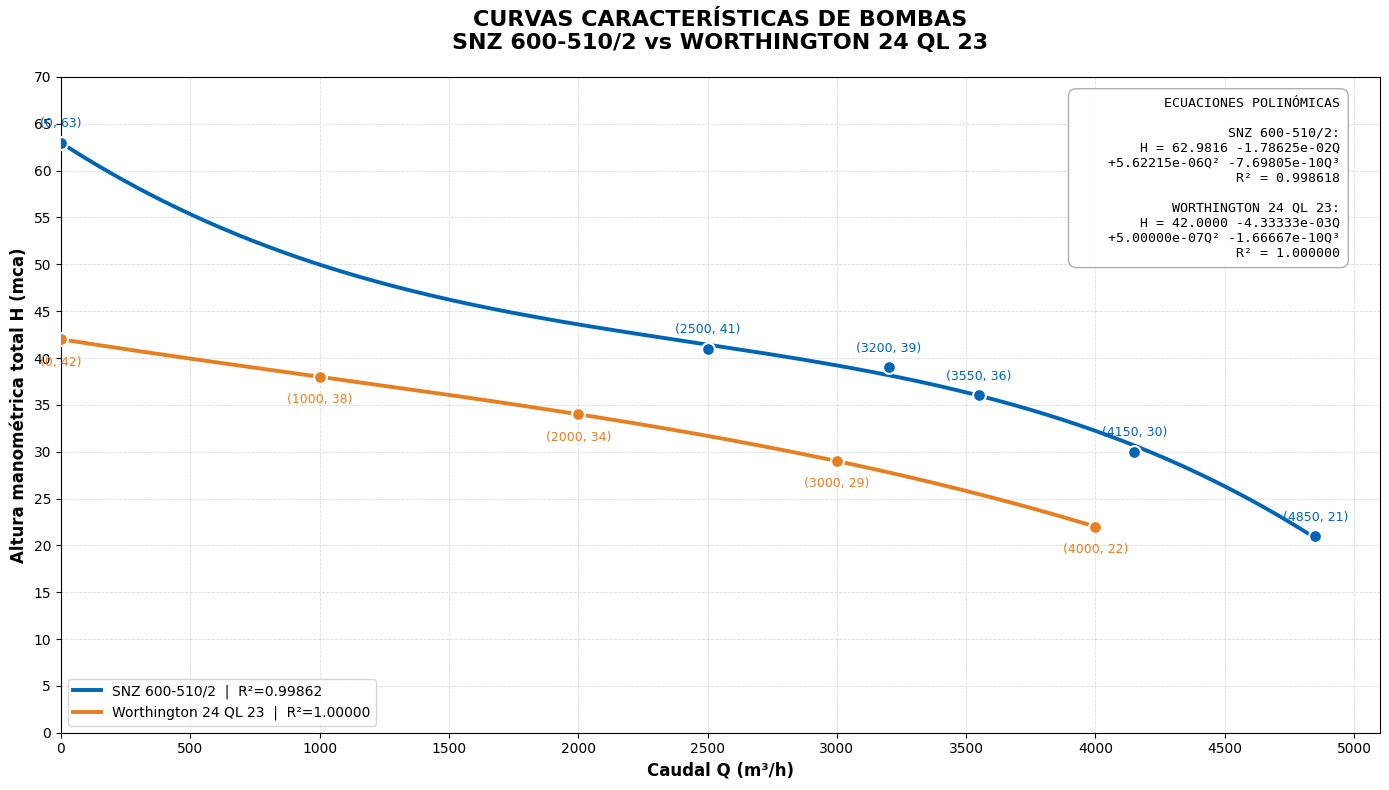

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:

# ============================================================
# CURVAS CARACTERÍSTICAS DE BOMBAS
# SNZ 600-510/2 Y WORTHINGTON 24 QL 23
# AJUSTES POLINÓMICOS DE TERCER GRADO
# GOOGLE COLAB
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# ============================================================
# 1. DATOS DE LAS BOMBAS
# ============================================================

# BOMBA 1 - SNZ 600-510/2
Q_SNZ = np.array([
    0, 2500, 3200, 3550, 4150, 4850
], dtype=float)

H_SNZ = np.array([
    63, 41, 39, 36, 30, 21
], dtype=float)

# BOMBA 2 - WORTHINGTON 24 QL 23
Q_W = np.array([
    0, 1000, 2000, 3000, 4000
], dtype=float)

H_W = np.array([
    42, 38, 34, 29, 22
], dtype=float)

# ============================================================
# 2. AJUSTES POLINÓMICOS
# ============================================================

grado = 3

coef_SNZ = np.polyfit(Q_SNZ, H_SNZ, grado)
coef_W = np.polyfit(Q_W, H_W, grado)

pol_SNZ = np.poly1d(coef_SNZ)
pol_W = np.poly1d(coef_W)

# Generación de curvas continuas
Q_curva_SNZ = np.linspace(
    Q_SNZ.min(), Q_SNZ.max(), 500
)

Q_curva_W = np.linspace(
    Q_W.min(), Q_W.max(), 500
)

H_curva_SNZ = pol_SNZ(Q_curva_SNZ)
H_curva_W = pol_W(Q_curva_W)

# ============================================================
# 3. CÁLCULO DE R²
# ============================================================

def calcular_r2(Q, H, polinomio):

    H_calculada = polinomio(Q)

    suma_residuos = np.sum(
        (H - H_calculada)**2
    )

    suma_total = np.sum(
        (H - np.mean(H))**2
    )

    return 1 - suma_residuos / suma_total


R2_SNZ = calcular_r2(Q_SNZ, H_SNZ, pol_SNZ)
R2_W = calcular_r2(Q_W, H_W, pol_W)

# ============================================================
# 4. MOSTRAR ECUACIONES
# ============================================================

def mostrar_polinomio(nombre, coeficientes, r2):

    a3, a2, a1, a0 = coeficientes

    print("\n" + "="*75)
    print(nombre)
    print("="*75)

    print("\nECUACIÓN POLINÓMICA:")
    print(
        f"H(Q) = {a0:.8f} "
        f"{a1:+.12e} Q "
        f"{a2:+.12e} Q² "
        f"{a3:+.12e} Q³"
    )

    print(f"\nR² = {r2:.8f}")
    print("Q en m³/h - H en mca")


mostrar_polinomio(
    "BOMBA SNZ 600-510/2",
    coef_SNZ,
    R2_SNZ
)

mostrar_polinomio(
    "BOMBA WORTHINGTON 24 QL 23",
    coef_W,
    R2_W
)

# ============================================================
# 5. GRÁFICO COMPARATIVO
# ============================================================

fig, ax = plt.subplots(figsize=(14, 8))

color_SNZ = "#0066B3"
color_W = "#E67E22"

# CURVA SNZ
ax.plot(
    Q_curva_SNZ,
    H_curva_SNZ,
    color=color_SNZ,
    linewidth=2.8,
    label=f"SNZ 600-510/2  |  R²={R2_SNZ:.5f}"
)

ax.scatter(
    Q_SNZ,
    H_SNZ,
    color=color_SNZ,
    s=85,
    edgecolor="white",
    linewidth=1.5,
    zorder=5
)

# CURVA WORTHINGTON
ax.plot(
    Q_curva_W,
    H_curva_W,
    color=color_W,
    linewidth=2.8,
    label=f"Worthington 24 QL 23  |  R²={R2_W:.5f}"
)

ax.scatter(
    Q_W,
    H_W,
    color=color_W,
    s=85,
    edgecolor="white",
    linewidth=1.5,
    zorder=5
)

# ============================================================
# 6. IDENTIFICACIÓN DE PUNTOS
# ============================================================

# Etiquetas SNZ (arriba de los puntos)
for q, h in zip(Q_SNZ, H_SNZ):

    ax.annotate(
        f"({q:.0f}, {h:.0f})",
        xy=(q, h),
        xytext=(0, 11),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color=color_SNZ
    )

# Etiquetas Worthington (debajo de los puntos)
for q, h in zip(Q_W, H_W):

    ax.annotate(
        f"({q:.0f}, {h:.0f})",
        xy=(q, h),
        xytext=(0, -19),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color=color_W
    )

# ============================================================
# 7. CONFIGURACIÓN DE EJES
# ============================================================

ax.set_title(
    "CURVAS CARACTERÍSTICAS DE BOMBAS\n"
    "SNZ 600-510/2 vs WORTHINGTON 24 QL 23",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Caudal Q (m³/h)",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Altura manométrica total H (mca)",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlim(0, 5100)
ax.set_ylim(0, 70)

ax.set_xticks(
    np.arange(0, 5101, 500)
)

ax.set_yticks(
    np.arange(0, 71, 5)
)

ax.grid(
    True,
    which="major",
    linestyle="--",
    linewidth=0.6,
    alpha=0.45
)

ax.tick_params(
    axis="both",
    labelsize=10
)

# ============================================================
# 8. LEYENDA Y ECUACIONES
# ============================================================

ax.legend(
    loc="lower left",
    fontsize=10,
    frameon=True
)

# Mostrar ambas ecuaciones dentro del gráfico
def ecuacion_corta(coef):
    a3, a2, a1, a0 = coef
    return (
        f"H = {a0:.4f} {a1:+.5e}Q\n"
        f"    {a2:+.5e}Q² {a3:+.5e}Q³"
    )

texto_ecuaciones = (
    "ECUACIONES POLINÓMICAS\n\n"
    "SNZ 600-510/2:\n"
    + ecuacion_corta(coef_SNZ)
    + f"\nR² = {R2_SNZ:.6f}\n\n"
    "WORTHINGTON 24 QL 23:\n"
    + ecuacion_corta(coef_W)
    + f"\nR² = {R2_W:.6f}"
)

ax.text(
    0.97,
    0.97,
    texto_ecuaciones,
    transform=ax.transAxes,
    fontsize=9.5,
    verticalalignment="top",
    horizontalalignment="right",
    family="monospace",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="white",
        edgecolor="#AAAAAA",
        alpha=0.95
    )
)

# ============================================================
# 9. EXPORTAR GRÁFICO
# ============================================================

plt.tight_layout()

nombre_archivo = (
    "Comparacion_Curvas_SNZ_Worthington.png"
)

plt.savefig(
    nombre_archivo,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ============================================================
# 10. DESCARGA AUTOMÁTICA
# ============================================================

files.download(nombre_archivo)
